# Week 8 — Survival Analysis
### *How long until it happens?* Modelling time-to-event with censoring
**SENG 42293 Big Data Analytics · LO3**

Many business questions are about **time until an event**: how long until a loyalty member cancels, a customer returns, a device fails, a patient relapses. Ordinary regression and simple averages fail here because of **censoring**: for some subjects the event has *not happened yet* when we stop watching.

**In this notebook:** why naive averages are wrong · the Kaplan-Meier estimator (built by hand, then checked against a library) · confidence bands · comparing groups with the log-rank test · hazard and cumulative hazard · the **Cox proportional-hazards model** · checking its assumptions · predicting survival curves · scaling with a **life table in Spark**.

**Data:** `data/member_tenure.csv`, a *synthetic* loyalty-programme dataset for the travel platform: 4,000 members, tenure in months until they cancel (event) or until the study ends (censored). Members join at different times (**staggered entry**), so later joiners are observed for less time.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
ACC, ACCL, CH, GREY = "#8b7355", "#c4b5a0", "#2a2a2a", "#999999"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=[ACC, "#2a2a2a", ACCL, "#b5651d", "#6b8e8e", GREY]),
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})
RES = {}                      # key numbers, reused in the slides and notes
def save(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", dpi=130); plt.show()

In [2]:
m = pd.read_csv("data/member_tenure.csv")
print(m.shape); display(m.head())
n, ev = len(m), int(m.cancelled.sum())
print(f"members: {n:,} | cancelled (event observed): {ev:,} ({ev/n:.1%}) | still active (censored): {n-ev:,} ({(n-ev)/n:.1%})")
RES.update(n=n, events=ev, censored_pct=round(100*(n-ev)/n, 1))

(4000, 8)


,member_id,plan,channel,avg_rating_given,bookings_year1,join_month,tenure_months,cancelled
0,M00001,free,social,4.5,1,11.68,9.28,1
1,M00002,free,social,2.7,0,2.16,8.71,1
2,M00003,free,direct,3.6,2,22.59,1.19,1
3,M00004,premium,social,3.8,5,12.15,11.85,0
4,M00005,free,search,4.6,3,10.13,5.95,1


members: 4,000 | cancelled (event observed): 1,711 (42.8%) | still active (censored): 2,289 (57.2%)


## 1. Censoring and why simple averages mislead
* **Event:** `cancelled = 1`. **Censored:** `cancelled = 0` (still a member when observation ended). We know they stayed *at least* `tenure_months`, nothing more.

Three tempting but wrong summaries:

mean of all observed tenures          :  8.86 months  (too low: censored members are cut short)
mean among cancelled members only     :  7.23 months  (too low: ignores long-stayers)


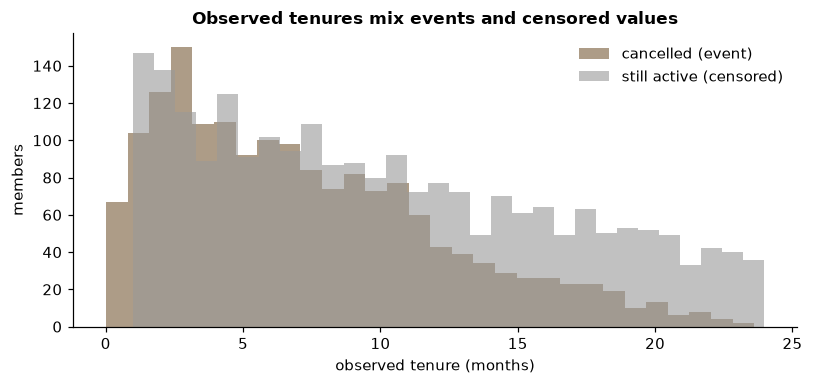

In [3]:
naive_all = m.tenure_months.mean()                                   # treats censored times as if they were cancellation times
naive_cancelled_only = m.loc[m.cancelled == 1, "tenure_months"].mean()   # throws away everyone who stayed (survivor-bias in reverse)
print(f"mean of all observed tenures          : {naive_all:5.2f} months  (too low: censored members are cut short)")
print(f"mean among cancelled members only     : {naive_cancelled_only:5.2f} months  (too low: ignores long-stayers)")
RES["naive_all"], RES["naive_cancelled"] = round(float(naive_all), 2), round(float(naive_cancelled_only), 2)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.hist(m.loc[m.cancelled == 1, "tenure_months"], bins=30, alpha=.7, color=ACC, label="cancelled (event)")
ax.hist(m.loc[m.cancelled == 0, "tenure_months"], bins=30, alpha=.6, color=GREY, label="still active (censored)")
ax.set_xlabel("observed tenure (months)"); ax.set_ylabel("members"); ax.set_title("Observed tenures mix events and censored values"); ax.legend(frameon=False); save("w08_censoring")

**The fix:** estimate the *survival function* S(t) = P(tenure > t) using both events and censored observations. A censored member contributes information up to the moment we stopped watching: they were *at risk* and did not cancel.

## 2. The Kaplan-Meier estimator, built by hand
At each distinct event time *t_i*: **d_i** = cancellations at *t_i*, **n_i** = members still at risk just before *t_i*.

**S(t) = Π over t_i ≤ t of (1 - d_i / n_i)**

Censored members leave the risk set without causing a drop.

In [4]:
T, E = m.tenure_months.values, m.cancelled.values
event_times = np.unique(T[E == 1])
S, surv, at_risk, deaths = 1.0, [], [], []
for t in event_times:
    n_i = (T >= t).sum(); d_i = ((T == t) & (E == 1)).sum()
    S *= 1 - d_i / n_i; surv.append(S); at_risk.append(n_i); deaths.append(d_i)
km_manual = pd.Series(surv, index=event_times)
print("first rows of the KM table:"); display(pd.DataFrame({"time": event_times[:5], "at risk": at_risk[:5], "events": deaths[:5], "S(t)": np.round(surv[:5], 4)}))

first rows of the KM table:


,time,at risk,events,S(t)
0,0.01,4000,1,0.9998
1,0.03,3999,2,0.9992
2,0.05,3997,3,0.9985
3,0.10,3994,1,0.9982
4,0.15,3993,1,0.9980


max difference between my implementation and lifelines: 8.33e-15
median tenure (S=0.5): 13.6 months | retention at 6/12/18/24 months: {6: 0.772, 12: 0.544, 18: 0.4, 24: 0.267}


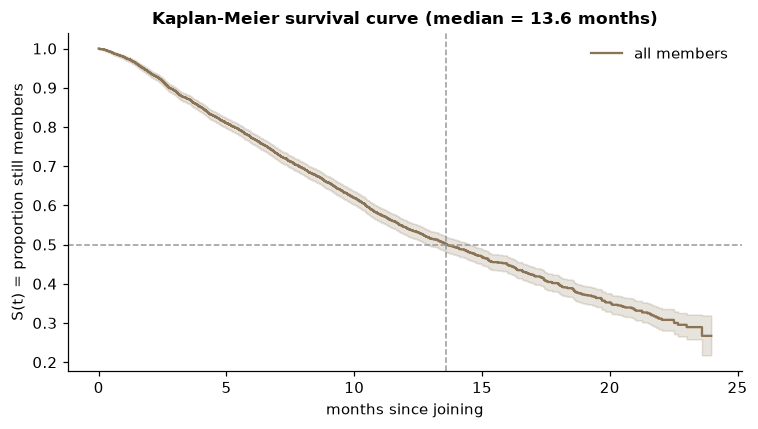

In [5]:
from lifelines import KaplanMeierFitter
kmf = KaplanMeierFitter().fit(T, E, label="all members")
check = np.abs(kmf.survival_function_at_times(event_times).values - km_manual.values).max()
print(f"max difference between my implementation and lifelines: {check:.2e}")
assert check < 1e-9
med = kmf.median_survival_time_
S_at = {k: float(kmf.survival_function_at_times(k).iloc[0]) for k in (6, 12, 18, 24)}
print(f"median tenure (S=0.5): {med:.1f} months | retention at 6/12/18/24 months:", {k: round(v, 3) for k, v in S_at.items()})
RES["km_median"], RES["km_S"] = round(float(med), 1), {k: round(v, 3) for k, v in S_at.items()}
fig, ax = plt.subplots(figsize=(7, 4)); kmf.plot_survival_function(ax=ax, color=ACC, ci_alpha=.2); ax.axhline(.5, color=GREY, ls="--", lw=1); ax.axvline(med, color=GREY, ls="--", lw=1)
ax.set_xlabel("months since joining"); ax.set_ylabel("S(t) = proportion still members"); ax.set_title(f"Kaplan-Meier survival curve (median = {med:.1f} months)"); ax.legend(frameon=False); save("w08_km")

The shaded band is a **95% confidence interval**: it widens on the right because few members remain at risk there. Never over-read the tail of a KM curve.

## 3. Comparing groups: curves and the log-rank test

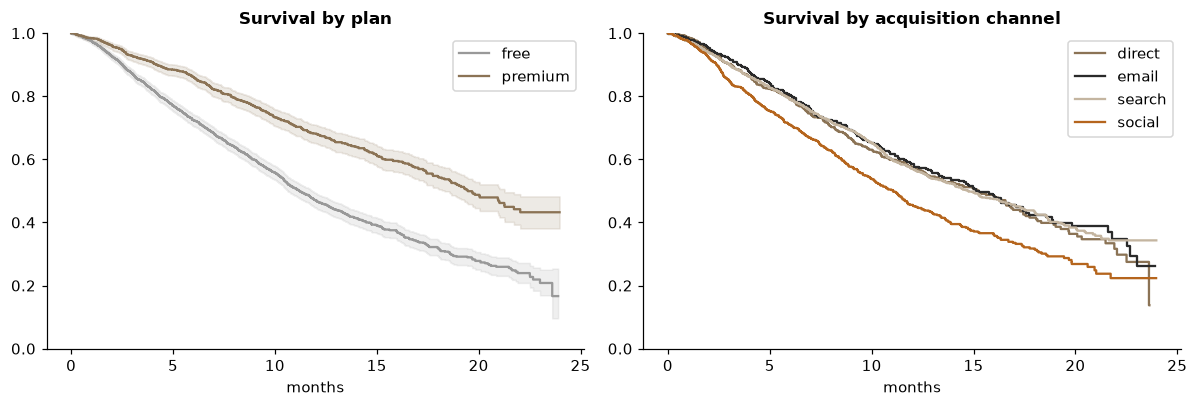

log-rank free vs premium : chi2=141.9, p=1.03e-32
log-rank across channels : chi2=41.7, p=4.75e-09
median tenure: {'free': 11.2, 'premium': 19.5} | 12-month retention: {'free': 0.47, 'premium': 0.682}


In [6]:
from lifelines.statistics import logrank_test, multivariate_logrank_test
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for g, c in zip(["free", "premium"], [GREY, ACC]):
    k = KaplanMeierFitter().fit(m.tenure_months[m.plan == g], m.cancelled[m.plan == g], label=g); k.plot_survival_function(ax=ax[0], color=c, ci_alpha=.15)
ax[0].set_title("Survival by plan"); ax[0].set_xlabel("months"); ax[0].set_ylim(0, 1)
for g in sorted(m.channel.unique()):
    KaplanMeierFitter().fit(m.tenure_months[m.channel == g], m.cancelled[m.channel == g], label=g).plot_survival_function(ax=ax[1], ci_show=False)
ax[1].set_title("Survival by acquisition channel"); ax[1].set_xlabel("months"); ax[1].set_ylim(0, 1)
save("w08_groups")
lr = logrank_test(m.tenure_months[m.plan == "free"], m.tenure_months[m.plan == "premium"], m.cancelled[m.plan == "free"], m.cancelled[m.plan == "premium"])
ch = multivariate_logrank_test(m.tenure_months, m.channel, m.cancelled)
print(f"log-rank free vs premium : chi2={lr.test_statistic:.1f}, p={lr.p_value:.2e}")
print(f"log-rank across channels : chi2={ch.test_statistic:.1f}, p={ch.p_value:.2e}")
med_by = {g: float(KaplanMeierFitter().fit(m.tenure_months[m.plan == g], m.cancelled[m.plan == g]).median_survival_time_) for g in ["free", "premium"]}
S12 = {g: float(KaplanMeierFitter().fit(m.tenure_months[m.plan == g], m.cancelled[m.plan == g]).survival_function_at_times(12).iloc[0]) for g in ["free", "premium"]}
print("median tenure:", {k: round(v, 1) for k, v in med_by.items()}, "| 12-month retention:", {k: round(v, 3) for k, v in S12.items()})
RES["logrank_plan_p"], RES["logrank_channel_p"] = float(lr.p_value), float(ch.p_value)
RES["med_by_plan"], RES["S12_by_plan"] = {k: round(v, 1) for k, v in med_by.items()}, {k: round(v, 3) for k, v in S12.items()}

The **log-rank test** asks: *could these curves have come from the same survival function?* A small p-value says no. It tells you the curves differ, not by *how much* or *why*; for that we need a regression model.

## 4. Hazard: the instantaneous risk
The **hazard** h(t) is the risk of cancelling *right now*, given the member is still here. The **cumulative hazard** H(t) = ∫h and survival are linked by **S(t) = exp(-H(t))**. Nelson-Aalen estimates H(t) directly.

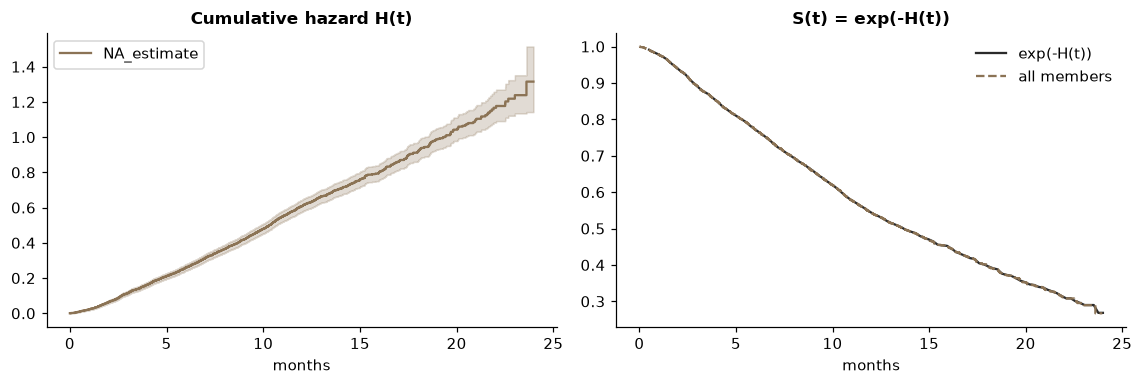

In [7]:
from lifelines import NelsonAalenFitter
naf = NelsonAalenFitter().fit(T, E)
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6)); naf.plot_cumulative_hazard(ax=ax[0], color=ACC); ax[0].set_title("Cumulative hazard H(t)"); ax[0].set_xlabel("months")
t = np.linspace(0.5, 24, 100); H = naf.cumulative_hazard_at_times(t).values; ax[1].plot(t, np.exp(-H), color=CH, label="exp(-H(t))"); kmf.plot_survival_function(ax=ax[1], ci_show=False, color=ACC, ls="--"); ax[1].set_title("S(t) = exp(-H(t))"); ax[1].legend(frameon=False); ax[1].set_xlabel("months")
save("w08_hazard")

The cumulative hazard is **convex** (it bends upward): the instantaneous risk of cancelling *increases* with tenure in this data (a Weibull shape greater than 1). A constant hazard would give a straight line and exponential survival.

## 5. The Cox proportional-hazards model
We want to know **which member characteristics change the risk of cancelling, and by how much**, while adjusting for the others.

**h(t | x) = h₀(t) · exp(β₁x₁ + β₂x₂ + …)**

* `h₀(t)` is an unspecified baseline hazard (the model is *semi-parametric*).
* `exp(β)` is a **hazard ratio (HR)**: HR = 0.6 means 40% lower instantaneous risk; HR = 1.4 means 40% higher.
* **Proportional hazards assumption:** covariate effects multiply the baseline by a constant over time.

,HR,HR low,HR high,p
covariate,,,,
premium,0.569,0.505,0.641,0.0
social_channel,1.460,1.315,1.622,0.0
avg_rating_given,0.623,0.585,0.663,0.0
bookings_year1,0.931,0.908,0.955,0.0


concordance index (c-index) = 0.642   (0.5 = random, 1.0 = perfect ranking)


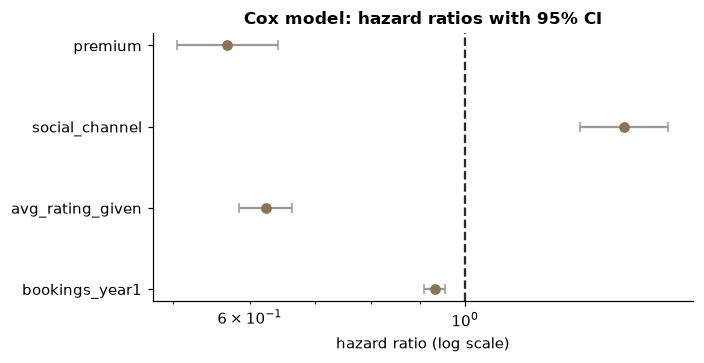

In [8]:
from lifelines import CoxPHFitter
X = pd.DataFrame({"tenure_months": m.tenure_months, "cancelled": m.cancelled, "premium": (m.plan == "premium").astype(int),
                  "social_channel": (m.channel == "social").astype(int), "avg_rating_given": m.avg_rating_given, "bookings_year1": m.bookings_year1})
cph = CoxPHFitter().fit(X, "tenure_months", "cancelled")
s = cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(3); s.columns = ["HR", "HR low", "HR high", "p"]
display(s); print(f"concordance index (c-index) = {cph.concordance_index_:.3f}   (0.5 = random, 1.0 = perfect ranking)")
RES["cox"] = s.reset_index().rename(columns={"covariate": "variable"}).to_dict("records"); RES["cindex"] = round(float(cph.concordance_index_), 3)
fig, ax = plt.subplots(figsize=(6.5, 3.4)); y = np.arange(len(s))[::-1]
ax.errorbar(s.HR, y, xerr=[s.HR - s["HR low"], s["HR high"] - s.HR], fmt="o", color=ACC, ecolor=GREY, capsize=3); ax.axvline(1, color=CH, ls="--")
ax.set_yticks(y, s.index); ax.set_xlabel("hazard ratio (log scale)"); ax.set_xscale("log"); ax.set_title("Cox model: hazard ratios with 95% CI"); save("w08_forest")

**Interpretation:** a hazard ratio below 1 (left of the dashed line) means the variable *protects* against cancelling; above 1 means it raises risk. Intervals that cross 1 are not statistically distinguishable from no effect.

### Does the model recover the truth?
Because this dataset is synthetic, we know the true effects used to generate it. Real data never gives you this check, so treat it as a calibration of your trust in the method.

In [9]:
truth = pd.Series({"premium": np.exp(-0.55), "social_channel": np.exp(0.35), "avg_rating_given": np.exp(-0.45), "bookings_year1": np.exp(-0.08)})
cmp = pd.DataFrame({"estimated HR": s.HR, "true HR": truth.round(3), "true HR inside 95% CI": [(truth[k] >= s.loc[k, "HR low"]) and (truth[k] <= s.loc[k, "HR high"]) for k in s.index]})
display(cmp); RES["recovers_truth"] = bool(cmp["true HR inside 95% CI"].all()); print("true HR inside the interval for all covariates:", RES["recovers_truth"])

,estimated HR,true HR,true HR inside 95% CI
premium,0.569,0.577,True
social_channel,1.460,1.419,True
avg_rating_given,0.623,0.638,True
bookings_year1,0.931,0.923,True


true HR inside the interval for all covariates: True


## 6. Checking the proportional-hazards assumption

In [10]:
from lifelines.statistics import proportional_hazard_test
ph = proportional_hazard_test(cph, X, time_transform="rank")
phs = ph.summary[["test_statistic", "p"]].round(3); display(phs)
RES["ph_min_p"] = float(phs.p.min())
print("Interpretation: small p (< 0.05) = evidence that the effect changes over time (assumption violated). Smallest p here:", round(float(phs.p.min()), 3))

,test_statistic,p
avg_rating_given,0.034,0.853
bookings_year1,0.199,0.655
premium,0.001,0.977
social_channel,0.012,0.913


Interpretation: small p (< 0.05) = evidence that the effect changes over time (assumption violated). Smallest p here: 0.655


If the assumption fails: **stratify** on that variable, add an interaction with time, or use a parametric/accelerated-failure-time model. Report it; do not hide it.

## 7. Prediction and what-if analysis

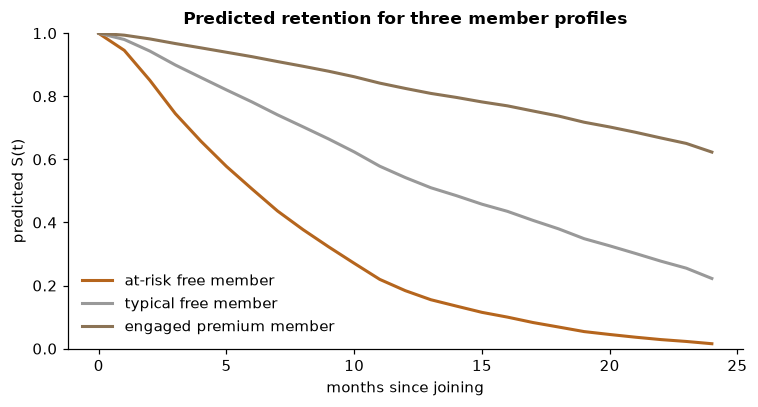

predicted 12-month retention: {'at-risk free member': 0.184, 'typical free member': 0.542, 'engaged premium member': 0.825}
typical free member: 12-month retention 0.542 -> 0.706 if upgraded to premium (+16.4 points)


In [11]:
profiles = pd.DataFrame({"premium": [0, 0, 1], "social_channel": [1, 0, 0], "avg_rating_given": [2.8, 3.7, 4.5], "bookings_year1": [1, 4, 7]},
                        index=["at-risk free member", "typical free member", "engaged premium member"])
curves = cph.predict_survival_function(profiles, times=np.arange(0, 25))
fig, ax = plt.subplots(figsize=(7, 3.8))
for c, col in zip(curves.columns, ["#b5651d", GREY, ACC]): ax.plot(curves.index, curves[c], color=col, lw=2, label=c)
ax.set_xlabel("months since joining"); ax.set_ylabel("predicted S(t)"); ax.set_ylim(0, 1); ax.set_title("Predicted retention for three member profiles"); ax.legend(frameon=False); save("w08_profiles")
ret12 = curves.loc[12].round(3).to_dict(); print("predicted 12-month retention:", ret12); RES["profile_ret12"] = ret12
# what-if: convert the typical free member to premium
base = profiles.loc[["typical free member"]].copy(); up = base.copy(); up["premium"] = 1
r0, r1 = float(cph.predict_survival_function(base, times=[12]).iloc[0, 0]), float(cph.predict_survival_function(up, times=[12]).iloc[0, 0])
print(f"typical free member: 12-month retention {r0:.3f} -> {r1:.3f} if upgraded to premium (+{100*(r1-r0):.1f} points)"); RES["upgrade_effect"] = {"before": round(r0, 3), "after": round(r1, 3)}

**Prescriptive link (Week 7):** the predicted retention gain, multiplied by the value of a retained member, is the *uplift* that a campaign optimiser would use. Survival models are the engine behind churn and retention decisions.

## 8. Survival analysis at scale: the life table in Spark
Kaplan-Meier needs a sort over all individuals, which is awkward on a cluster. The standard trick: **reduce to a life table** by grouping time into intervals. Spark counts events and censorings per interval (a `groupBy`, one shuffle); the final product-limit calculation runs on the tiny table.

In [12]:
import sys; os.environ["PYSPARK_PYTHON"] = sys.executable
from pyspark.sql import SparkSession, functions as F
spark = SparkSession.builder.master("local[*]").config("spark.ui.enabled", "false").getOrCreate(); spark.sparkContext.setLogLevel("ERROR")
sdf = spark.read.csv("data/member_tenure.csv", header=True, inferSchema=True).withColumn("k", F.floor("tenure_months").cast("int"))
tab = (sdf.groupBy("k").agg(F.sum("cancelled").alias("d"), F.sum(1 - F.col("cancelled")).alias("c")).orderBy("k").collect())
lt = pd.DataFrame([r.asDict() for r in tab]).fillna(0)
lt["n_start"] = lt[["d", "c"]].sum(1)[::-1].cumsum()[::-1]             # members entering interval k
lt["n_eff"] = lt.n_start - lt.c / 2                                       # actuarial adjustment: censored members at risk for half the interval
lt["q"] = lt.d / lt.n_eff; lt["S_end"] = (1 - lt.q).cumprod()
display(lt.head(6).round(3))
S12_life = float(lt.loc[lt.k == 11, "S_end"].iloc[0]); S12_km = float(kmf.survival_function_at_times(12).iloc[0])
print(f"S(12): life table (Spark) = {S12_life:.3f} | exact Kaplan-Meier = {S12_km:.3f}")
RES["S12_life"], RES["S12_km"] = round(S12_life, 3), round(S12_km, 3)
spark.stop()

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=44265 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=
Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=44265 -Dhttp.nonProxyHosts=localhost|127.0.0.1

26/10/13 08:42:31 WARN Utils: Your hostname, vm resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/10/13 08:42:31 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/13 08:42:32 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


,k,d,c,n_start,n_eff,q,S_end
0,0,86,0,4000,4000.0,0.022,0.978
1,1,154,175,3914,3826.5,0.040,0.939
2,2,175,183,3585,3493.5,0.050,0.892
3,3,147,122,3227,3166.0,0.046,0.851
4,4,137,154,2958,2881.0,0.048,0.810
5,5,123,123,2667,2605.5,0.047,0.772


S(12): life table (Spark) = 0.545 | exact Kaplan-Meier = 0.544


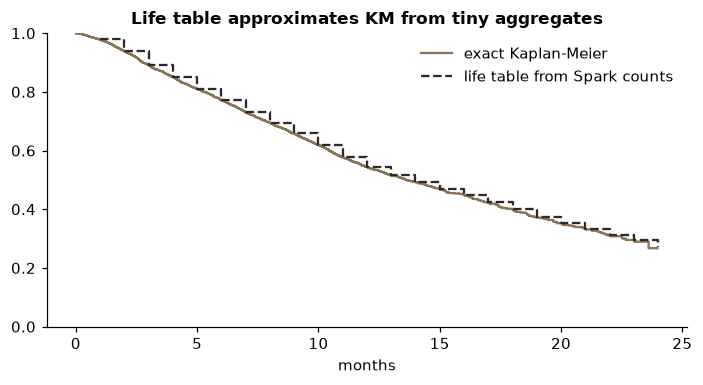

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 3.6)); kmf.plot_survival_function(ax=ax, ci_show=False, color=ACC, label="exact Kaplan-Meier")
ax.step(lt.k + 1, lt.S_end, where="post", color=CH, ls="--", label="life table from Spark counts"); ax.set_xlabel("months"); ax.set_ylim(0, 1); ax.legend(frameon=False); ax.set_title("Life table approximates KM from tiny aggregates"); save("w08_lifetable")

## 9. Exercises
1. Compute the **restricted mean survival time** up to 24 months from the KM curve (area under it). What does it mean in business terms?
2. Fit separate KM curves for `avg_rating_given >= 4` vs `< 4`. Is the log-rank p-value consistent with the Cox hazard ratio?
3. Add `premium * social_channel` as an interaction to the Cox model. Is it significant? (We know the truth: it is not in the generating process.)
4. Re-run section 1 after removing all members who joined in the last 6 months. Do the naive averages move closer to the KM estimate? Why?
5. A retention campaign costs 5 units per member and retains 10% more members at 12 months. Using the Cox model and a value per retained member, decide who to target (link to Week 7).

In [14]:
json.dump(RES, open("results/w08.json", "w"), indent=1); print(json.dumps(RES)[:900])

{"n": 4000, "events": 1711, "censored_pct": 57.2, "naive_all": 8.86, "naive_cancelled": 7.23, "km_median": 13.6, "km_S": {"6": 0.772, "12": 0.544, "18": 0.4, "24": 0.267}, "logrank_plan_p": 1.0348458663582596e-32, "logrank_channel_p": 4.745121663137777e-09, "med_by_plan": {"free": 11.2, "premium": 19.5}, "S12_by_plan": {"free": 0.47, "premium": 0.682}, "cox": [{"variable": "premium", "HR": 0.569, "HR low": 0.505, "HR high": 0.641, "p": 0.0}, {"variable": "social_channel", "HR": 1.46, "HR low": 1.315, "HR high": 1.622, "p": 0.0}, {"variable": "avg_rating_given", "HR": 0.623, "HR low": 0.585, "HR high": 0.663, "p": 0.0}, {"variable": "bookings_year1", "HR": 0.931, "HR low": 0.908, "HR high": 0.955, "p": 0.0}], "cindex": 0.642, "recovers_truth": true, "ph_min_p": 0.655, "profile_ret12": {"at-risk free member": 0.184, "typical free member": 0.542, "engaged premium member": 0.825}, "upgrade_e
